In [6]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ---------------------------------------- 0/4 [threadpoolctl]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ------------

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


In [9]:
# Baca dataset
df = pd.read_csv("news_data.csv")

# Cek nama kolom dulu
print("Kolom yang tersedia:", df.columns.tolist())

# Ganti nama kolom jika perlu
text_column = "article_text"  # <- ubah ini kalau nama kolommu berbeda

# Hapus data kosong
df = df.dropna(subset=[text_column])

# Ambil sampel
sample = df[text_column].head(1000).astype(str).tolist()
print(f" Jumlah dokumen: {len(sample)}")

Kolom yang tersedia: ['title', 'author', 'publish_date', 'article_text', 'url', 'main_image', 'tag']
 Jumlah dokumen: 1000


In [11]:
# Buat model BoW
vectorizer_bow = CountVectorizer(max_features=5000)
bow_matrix = vectorizer_bow.fit_transform(sample)

print(" Shape matriks BoW:", bow_matrix.shape)
print("Jumlah kata unik:", len(vectorizer_bow.vocabulary_))

# Lihat daftar kata
vocab = vectorizer_bow.get_feature_names_out()
print("\n Contoh kata:", vocab[:20])

# Lihat hasil dokumen pertama
doc_vector = bow_matrix[0].toarray()[0]
nonzero = np.where(doc_vector > 0)[0]

print("\n Dokumen 1:")
print(sample[0][:150], "...")
print("\n Representasi BoW:")
for idx in nonzero:
    print(f"  {vocab[idx]:<20} : {int(doc_vector[idx])}")

 Shape matriks BoW: (1000, 5000)
Jumlah kata unik: 5000

 Contoh kata: ['00' '000' '004' '01' '02' '03' '05' '08' '09' '10' '100' '11' '110'
 '114' '12' '120' '121' '13' '14' '15']

 Dokumen 1:
Sekjen PDIP sekaligus Sekretaris Tim Pemenang Nasional (TPN) Ganjar Pranowo-Mahfud MD, Hasto Kristiyanto, ingin debat calon presiden dan calon wakil p ...

 Representasi BoW:
  10                   : 1
  12                   : 1
  2023                 : 1
  ada                  : 6
  adalah               : 1
  adu                  : 1
  advertisement        : 1
  agar                 : 1
  awal                 : 1
  bagi                 : 1
  bahwa                : 2
  baik                 : 2
  banten               : 1
  betul                : 2
  bisa                 : 2
  bukan                : 1
  calon                : 2
  capres               : 1
  cawapres             : 1
  content              : 1
  continue             : 1
  dalam                : 1
  dan                  : 3
  dari    

In [15]:
doc_idx = 0
doc_vector = bow_matrix[doc_idx].toarray()[0]
nonzero_idx = np.where(doc_vector > 0)[0]

print(f"\nDokumen {doc_idx+1}:")
print(sample[doc_idx][:150], "...\n")
print(" Representasi BoW:")
for idx in nonzero_idx:
    print(f"  {vocab[idx]:<20} : {int(doc_vector[idx])}")


Dokumen 1:
Sekjen PDIP sekaligus Sekretaris Tim Pemenang Nasional (TPN) Ganjar Pranowo-Mahfud MD, Hasto Kristiyanto, ingin debat calon presiden dan calon wakil p ...

 Representasi BoW:
  10                   : 1
  12                   : 1
  2023                 : 1
  ada                  : 6
  adalah               : 1
  adu                  : 1
  advertisement        : 1
  agar                 : 1
  awal                 : 1
  bagi                 : 1
  bahwa                : 2
  baik                 : 2
  banten               : 1
  betul                : 2
  bisa                 : 2
  bukan                : 1
  calon                : 2
  capres               : 1
  cawapres             : 1
  content              : 1
  continue             : 1
  dalam                : 1
  dan                  : 3
  dari                 : 1
  debat                : 8
  dengan               : 2
  di                   : 3
  dia                  : 1
  dirinya              : 1
  diselenggarakan      : 1
  g

In [16]:
vocab = vectorizer_bow.get_feature_names_out()
print("Contoh vocabulary:", vocab[:20])

Contoh vocabulary: ['00' '000' '004' '01' '02' '03' '05' '08' '09' '10' '100' '11' '110'
 '114' '12' '120' '121' '13' '14' '15']


In [14]:
total_elemen = bow_matrix.shape[0] * bow_matrix.shape[1]
elemen_non_nol = bow_matrix.nnz
sparsity = 1 - (elemen_non_nol / total_elemen)

print("Statistik Matriks BoW:")
print(f"  Total elemen       : {total_elemen:,}")
print(f"  Elemen bukan nol   : {elemen_non_nol:,}")
print(f"  Tingkat kekosongan : {sparsity:.4%}")

Statistik Matriks BoW:
  Total elemen       : 5,000,000
  Elemen bukan nol   : 172,811
  Tingkat kekosongan : 96.5438%


In [18]:
# Buat model TF-IDF
vectorizer_tfidf = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer_tfidf.fit_transform(sample)

print("Shape matriks TF-IDF:", tfidf_matrix.shape)

# Fungsi ambil kata terpenting
def get_top_words(doc_index, matriks, fitur_names, top_n=10):
    vektor = matriks[doc_index].toarray()[0]
    urutan = vektor.argsort()[::-1][:top_n]
    hasil = []
    for i in urutan:
        if vektor[i] > 0:
            hasil.append((fitur_names[i], round(vektor[i], 4)))
    return hasil

fitur = vectorizer_tfidf.get_feature_names_out()

# Tampilkan 10 kata terpenting
print(f"\n 10 Kata Terpenting — Dokumen 1:")
print(sample[0][:150], "...\n")
for kata, bobot in get_top_words(0, tfidf_matrix, fitur):
    print(f"  {kata:<20} : {bobot}")

Shape matriks TF-IDF: (1000, 5000)

 10 Kata Terpenting — Dokumen 1:
Sekjen PDIP sekaligus Sekretaris Tim Pemenang Nasional (TPN) Ganjar Pranowo-Mahfud MD, Hasto Kristiyanto, ingin debat calon presiden dan calon wakil p ...

  pertarungan          : 0.3786
  debat                : 0.3567
  gagasan              : 0.2792
  hasto                : 0.2236
  tpn                  : 0.2224
  pemimpin             : 0.1912
  rekayasa             : 0.1775
  yang                 : 0.1632
  pakta                : 0.1599
  intimidasi           : 0.1551


In [20]:
# Ambil 5 dokumen pertama
lima_dokumen = tfidf_matrix[:5]
matriks_kesamaan = cosine_similarity(lima_dokumen)

print(" Matriks Cosine Similarity:")
print(np.round(matriks_kesamaan, 3))

 Matriks Cosine Similarity:
[[1.    0.083 0.069 0.036 0.047]
 [0.083 1.    0.076 0.043 0.052]
 [0.069 0.076 1.    0.065 0.085]
 [0.036 0.043 0.065 1.    0.053]
 [0.047 0.052 0.085 0.053 1.   ]]


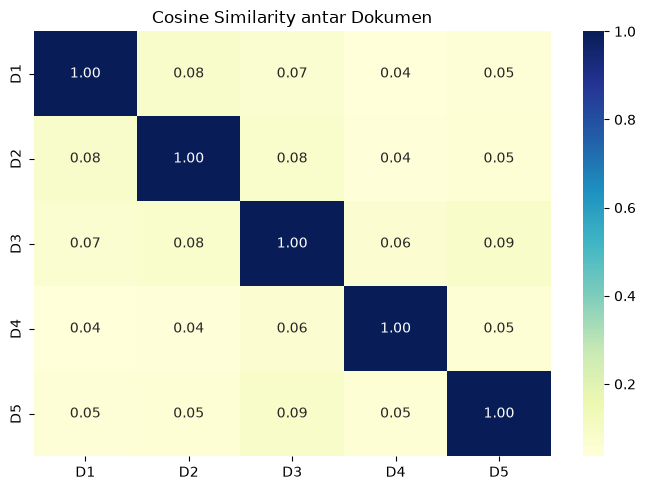

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    matriks_kesamaan,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"D{i+1}" for i in range(5)],
    yticklabels=[f"D{i+1}" for i in range(5)]
)
plt.title("Cosine Similarity antar Dokumen")
plt.tight_layout()
plt.show()

In [22]:
def cari_dokumen(kueri, vectorizer, matriks, daftar_dokumen, jumlah=5):
    vektor_kueri = vectorizer.transform([kueri])
    skor = cosine_similarity(vektor_kueri, matriks)[0]
    teratas = skor.argsort()[::-1][:jumlah]
    hasil = []
    for idx in teratas:
        hasil.append({
            "no": idx + 1,
            "skor": round(skor[idx], 4),
            "teks": daftar_dokumen[idx][:100]
        })
    return hasil

# Coba cari
kata_kunci = "kualitas bagus harga terjangkau"
hasil = cari_dokumen(kata_kunci, vectorizer_tfidf, tfidf_matrix, sample)

print(f"Kata Kunci: '{kata_kunci}'")
print("=" * 60)
for h in hasil:
    print(f"{h['no']}. [Skor: {h['skor']}]")
    print(f"   {h['teks']}...\n")

Kata Kunci: 'kualitas bagus harga terjangkau'
925. [Skor: 0.2712]
   Calon presiden nomor urut 1 Anies Rasyid Baswedan mendapat keluhan harga bahan pokok yang mahal keti...

975. [Skor: 0.2546]
   Calon presiden nomor urut 1 Anies Baswedan mengatakan ingin menekan harga kebutuhan pokok dalam 100 ...

932. [Skor: 0.2334]
   Calon Presiden dari Koalisi Perubahan Untuk Persatuan Anies Rasyid Baswedan berkampanye di Karawang,...

945. [Skor: 0.1883]
   Calon wakil presiden (cawapres) nomor urut 1 Muhaimin Iskandar (Cak Imin) menyambangi Pasar Raya Pad...

646. [Skor: 0.1844]
   Istri calon presiden (capres) nomor urut 3 Ganjar Pranowo, Siti Atikoh, menyoroti kondisi harga semb...



In [25]:
print("=" * 60)
print("PERBANDINGAN BoW vs TF-IDF")
print("=" * 60)

indeks_dokumen = 0

# Ambil nilai dari kedua metode
vektor_bow = vectorizer_bow.transform([sample[indeks_dokumen]]).toarray()[0]
vektor_tfidf = vectorizer_tfidf.transform([sample[indeks_dokumen]]).toarray()[0]

kata_bow = vectorizer_bow.get_feature_names_out()

print(f"\n Dokumen: {sample[indeks_dokumen][:100]}...")

# Tampilkan BoW
print("\n BoW — Frekuensi Kata:")
daftar_bow = [(kata_bow[i], int(vektor_bow[i])) 
              for i in range(len(vektor_bow)) if vektor_bow[i] > 0]
daftar_bow.sort(key=lambda x: x[1], reverse=True)
for kata, nilai in daftar_bow[:10]:
    print(f"  {kata:<20} : {nilai}")

# Tampilkan TF-IDF
print("\n TF-IDF — Bobot Kata:")
for kata, bobot in get_top_words(indeks_dokumen, tfidf_matrix, fitur):
    print(f"  {kata:<20} : {bobot}")

print("\n Selesai!")

PERBANDINGAN BoW vs TF-IDF

 Dokumen: Sekjen PDIP sekaligus Sekretaris Tim Pemenang Nasional (TPN) Ganjar Pranowo-Mahfud MD, Hasto Kristiy...

 BoW — Frekuensi Kata:
  yang                 : 11
  debat                : 8
  ada                  : 6
  gagasan              : 5
  itu                  : 4
  pemimpin             : 4
  pertarungan          : 4
  tpn                  : 4
  dan                  : 3
  di                   : 3

 TF-IDF — Bobot Kata:
  pertarungan          : 0.3786
  debat                : 0.3567
  gagasan              : 0.2792
  hasto                : 0.2236
  tpn                  : 0.2224
  pemimpin             : 0.1912
  rekayasa             : 0.1775
  yang                 : 0.1632
  pakta                : 0.1599
  intimidasi           : 0.1551

 Selesai!
